In [1]:
import lightweaver as lw 

from lightweaver.fal import Falc82 # essentially not needed 

from lightweaver.rh_atoms import H_6_atom, C_atom, O_atom, Si_atom, Al_atom, \
CaII_atom, Fe23_atom, He_9_atom, Mg_atom, N_atom, NaI_fine_atom, S_atom # Specific atomic models that cover most of 
                                                                        # of the spectral lines studied in solar physccs 

from custom_atoms import sr_tanausu                                                                

import matplotlib.pyplot as plt
import time
import numpy as np
import sys

In [5]:
from minimal_synth import synth

In [6]:
atlas = np.loadtxt("4607_4.txt",unpack=True, usecols=(0,1), delimiter=",", skiprows=1)

In [ ]:
atmos_start = Falc82()
wave = np.linspace(460.72, 460.75, 601)

# A test with given electrons:
Ie, ctxo = synth(atmos_start, conserve=False, useNe=True, prd=False, stokes=False, wave=lw.air_to_vac(wave), mu=1.0, actives='Sr')

atmos_start_lte_e = Falc82()

# A test with LTE electrons:
Icale, ctxcalc = synth(atmos_start_lte_e, conserve=False, useNe=False, prd=False, stokes=False, wave=lw.air_to_vac(wave), mu=1.0, actives='Sr')

LTE Iterations 1 (-- slowest convergence)
LTE Iterations 1 (He slowest convergence)


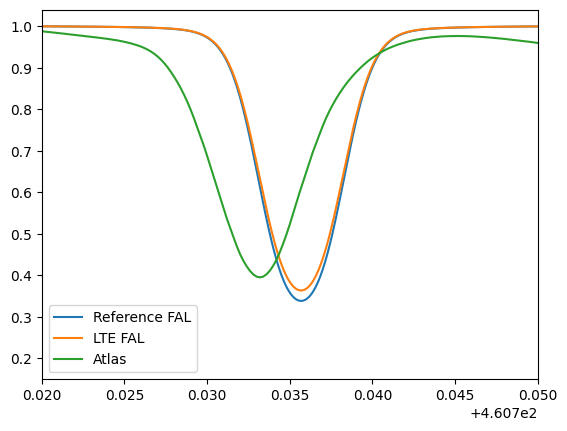

In [8]:
plt.clf()
plt.cla()
plt.plot(wave, Ie[0]/np.amax(Ie[0]), label='Reference FAL')
plt.plot(wave, Icale[0]/np.amax(Icale[0]), label='LTE FAL')
#plt.plot(wave, Icalelte[0]/np.amax(Icalelte[0]), label='LTE FAL, forced LTE solution')
plt.plot(atlas[0]/10.0, atlas[1]/np.amax(atlas[1]), label='Atlas')
plt.xlim(460.72, 460.75)
plt.legend()
plt.savefig("testme.png")

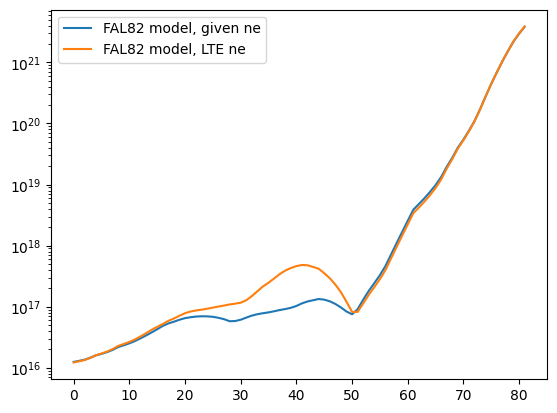

In [6]:
plt.semilogy(ctxo.atmos.ne, label='FAL82 model, given ne')
plt.semilogy(ctxcalc.atmos.ne, label='FAL82 model, LTE ne')
plt.legend()


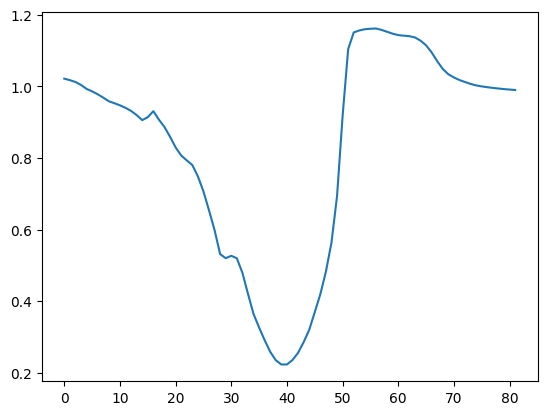

In [7]:
plt.plot(ctxo.atmos.ne/ctxcalc.atmos.ne)

Why electrons matter? 

Consider Sr only:

$$\frac{n_{Sr+} n_e}{n_{Sr}} = f$$
$$n_{Sr+} + n_{Sr} = k$$
$$\frac{n_{Sr} f}{n_e} + n_{Sr} = k$$
$$n_{Sr} = \frac{k}{1+f/n_e}$$